# FinWise AI · Production Machine Learning Pipeline Demonstration
### End-to-End Walkthrough: Transaction Ingestion, Behavioral K-Means Clustering, and KNN Purchase Affordability Classification

[![Python 3.12](https://img.shields.io/badge/Python-3.12-blue.svg)](https://www.python.org/)
[![Scikit-Learn](https://img.shields.io/badge/Scikit--Learn-1.6+-orange.svg)](https://scikit-learn.org/)
[![Status](https://img.shields.io/badge/Status-Production%20Grade-emerald.svg)]()
[![Platform](https://img.shields.io/badge/Platform-Jupyter%20%7C%20Colab%20%7C%20VS%20Code-purple.svg)]()

---

## Executive Overview & Pipeline Objectives

FinWise AI is an intelligent personal finance platform designed to replace generic budgeting rules with personalized, machine-learning-driven financial decision assistance. Rather than relying on rigid, one-size-fits-all heuristics (such as the standard 50/30/20 rule), the application derives behavioral patterns directly from historical user transactions and models purchase affordability under uncertainty.

This interactive demonstration notebook walks through the complete Machine Learning lifecycle across three core modules:

1. **Data Ingestion & Preprocessing Pipeline:**
   - Robust parsing and validation of heterogeneous transaction streams.
   - Handling missing values and zero-variance features.
   - Column-specific feature transformations using Scikit-Learn's `ColumnTransformer`, standardizing numeric continuous attributes with `StandardScaler` while preserving nominal attributes via `OneHotEncoder`.

2. **Unsupervised Learning — K-Means Spending Clustering:**
   - Rolling feature extraction aggregating raw transactions into monthly behavioral vectors: transaction frequency, average transaction size, savings ratio, discretionary ratio, daily spending variance, and 30-day burn rate.
   - Hyperparameter selection using the **Elbow Method (Inertia)** and **Silhouette Coefficient Analysis** across $k \in [2, 6]$.
   - Fitting $k=3$ behavioral profiles and applying dynamic centroid ranking to label archetypes: **Light Consumer**, **Balanced Consumer**, and **Heavy Consumer**.
   - Dimensionality reduction via **2D Principal Component Analysis (PCA)** for visual validation.

3. **Supervised Learning — K-Nearest Neighbors (KNN) Purchase Classifier:**
   - Formulating discretionary purchase affordability as a multi-class ordinal classification problem with 4 risk tiers: **Strong Yes**, **Cautious Yes**, **Better Wait**, and **No**.
   - Engineering 13 domain-specific liquidity, ratio, timing, and goal-distance features.
   - Training a distance-weighted K-Nearest Neighbors classifier ($w_i = 1/d(x, x_i)$) with stratified validation.
   - Comprehensive model evaluation: Confusion Matrix heatmap, Classification Report (Precision, Recall, F1-Score), and comparison against baseline models.

4. **Live Interactive Inference Simulation:**
   - Simulating an end-to-end evaluation for an authentic real-world dilemma: e.g., a $450 electronics purchase against a $1,200 liquid balance, upcoming $1,500 goal milestone, and "Balanced Consumer" behavioral baseline.
   - Generating calibrated posterior probability distributions and rendering an executive decision card.

---

### Machine Learning Architecture Diagram

```
[ Raw Transaction Ledger ] (CSV / SQLite Store)
          │
          ▼
[ 1. Data Ingestion & Validation ] ──► Missing Value Imputation & Schema Standardization
          │
          ├──► [ Scikit-Learn ColumnTransformer ] ──► StandardScaler + OneHotEncoder
          │
          ▼
[ 2. Monthly Behavioral Aggregation ] ──► (Frequency, Burn Rate, Discretionary Ratio, Variance)
          │
          ├──► Hyperparameter Optimization: Elbow Method & Silhouette Scores (k=2..6)
          │
          ▼
[ K-Means Clustering (k=3) ] ──► Dynamic Centroid Scoring ──► [ Light | Balanced | Heavy Consumer ]
          │
          ▼
[ 3. Purchase Context Feature Assembly ] ──► (13 Engineered Ratios, Goal Gaps, Consumer Flags)
          │
          ▼
[ Supervised KNN Classifier ] ──► Inverse-Distance Voting (k=7)
          │
          ▼
[ 4. Probability Calibration & Decision Card ] ──► [ Strong Yes | Cautious Yes | Better Wait | No ]
```


In [1]:
# =============================================================================
# Cell 0.1: Environment Setup, Dependencies & Publication Theming
# =============================================================================

import sys
import os
import warnings
from pathlib import Path

# Suppress non-critical runtime and sklearn convergence warnings for presentation
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Numerical & Data Processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Scikit-Learn ML Components
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, confusion_matrix, classification_report, f1_score, accuracy_score
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

# Configure publication-grade plot styles
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
    "figure.dpi": 110,
    "figure.autolayout": False,
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 1.2,
    "grid.color": "#E2E8F0",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})

# Curated FinWise AI aesthetic color palette
PALETTE = {
    "primary": "#0F766E",       # Deep Emerald Teal
    "secondary": "#10B981",     # Vibrant Mint
    "accent": "#F59E0B",        # Golden Amber
    "danger": "#EF4444",        # Crimson Coral
    "purple": "#6366F1",        # Electric Indigo
    "dark": "#1E293B",          # Slate Navy
    "light": "#F8FAFC",         # Cloud White
    "gray": "#64748B",          # Muted Slate
}

# Determine project root and module import strategy
PROJECT_ROOT = Path(os.getcwd()).resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Safe Import Strategy: detect local project modules or load standalone fallbacks
try:
    from utils.data_loader import DEFAULT_DATA_PATH, load_transactions
    from models.purchase_features import PURCHASE_FEATURE_COLUMNS, CATEGORY_IMPACT_WEIGHTS
    from models.spending_clustering import CLUSTER_FEATURES, PROFILE_NAMES
    print("✓ Successfully loaded FinWise AI native Python modules from project workspace.")
    REPO_AVAILABLE = True
except ImportError:
    print("ℹ Running in standalone / isolated environment: initializing robust embedded domain fallbacks.")
    REPO_AVAILABLE = False
    PURCHASE_FEATURE_COLUMNS = [
        "item_cost_balance_ratio", "item_cost_monthly_income_ratio", "days_left_in_month",
        "goal_urgency", "category_impact_weight", "monthly_expense_ratio", "savings_rate",
        "discretionary_spending_share", "nearest_goal_days_left", "goal_gap_ratio",
        "consumer_heavy_flag", "consumer_light_flag", "consumer_balanced_flag"
    ]
    CATEGORY_IMPACT_WEIGHTS = {
        "Housing": 1.0, "Food": 0.9, "Transportation": 0.75, "Entertainment": 0.35,
        "Health": 1.0, "Education": 0.7, "Other": 0.5
    }
    CLUSTER_FEATURES = [
        "transaction_frequency", "average_transaction_amount", "savings_ratio",
        "discretionary_ratio", "spending_variance", "monthly_burn_rate"
    ]
    PROFILE_NAMES = ["Light Consumer", "Balanced Consumer", "Heavy Consumer"]

print(f"✓ NumPy: {np.__version__} | Pandas: {pd.__version__} | Matplotlib | Scikit-Learn initialized.")


2026-10-03 01:09:31.269 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-03 01:09:31.272 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-03 01:09:31.274 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-03 01:09:31.276 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-03 01:09:31.280 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


✓ Successfully loaded FinWise AI native Python modules from project workspace.
✓ NumPy: 2.5.3 | Pandas: 3.0.6 | Matplotlib | Scikit-Learn initialized.


---
# Section 1: Data Ingestion & Preprocessing Pipeline

### Financial Transaction Schema Definition

Financial ledgers present unique preprocessing challenges: monetary inflows and outflows span orders of magnitude (from a $3.50 coffee to a $1,800 rent check), while dates and categories define structured temporal and semantic groupings.

The FinWise canonical transaction ledger adheres to a 5-column atomic schema:

| Column Name | Data Type | Permitted Values / Constraints | Financial Meaning |
| :--- | :--- | :--- | :--- |
| `date` | `datetime64[ns]` | ISO-8601 (`YYYY-MM-DD`), non-future | Transaction execution timestamp |
| `type` | `string (categorical)` | `{"income", "expense"}` | Directionality of cash flow |
| `category` | `string (categorical)` | `{"Salary", "Housing", "Food", "Transportation", "Entertainment", "Health", "Education", ...}` | Budgetary allocation domain |
| `amount` | `float64` | Strictly positive ($> 0.00$) | Magnitude in USD |
| `description` | `string` | Text string ($\le$ 120 characters) | Merchant name or ledger narrative |

### Mathematical Rationale for Feature Scaling

Distance-based algorithms—including **K-Means clustering** and **K-Nearest Neighbors**—compute Euclidean distances in an $N$-dimensional vector space:

$$d(\\mathbf{x}, \\mathbf{y}) = \\sqrt{\\sum_{i=1}^N (x_i - y_i)^2}$$

If features remain on unscaled scales:
- An unscaled expense amount of $\\$1,450.00$ produces squared differences on the order of $(1450 - 50)^2 = 1.96 \\times 10^6$.
- Meanwhile, an engineered ratio like `savings_rate` (typically spanning $[-0.5, +0.6]$) produces squared differences on the order of $(0.40 - 0.10)^2 = 0.09$.

Without standardization, the continuous dollar amounts would dictate $>99.99\\%$ of cluster assignments and nearest-neighbor lookups, rendering behavioral ratios mathematically invisible.

To resolve this, we implement **Z-score Standardization**:

$$z_i = \\frac{x_i - \\mu_i}{\\sigma_i}$$

where $\\mu_i$ is the empirical feature mean and $\\sigma_i$ is the standard deviation. Categorical features (`type`, `category`) are encoded via **One-Hot Encoding** (`handle_unknown='ignore'`), mapping nominal labels to an orthogonal binary vector space without imposing false ordinal hierarchies.


In [2]:
# =============================================================================
# Cell 1.1: Transaction Ingestion & Comprehensive Ledger Exploration
# =============================================================================

def load_or_generate_ledger_data() -> pd.DataFrame:
    """Load the bundled transaction ledger or generate an authentic 6-month history."""
    csv_candidates = [
        PROJECT_ROOT / "data" / "transactions.csv",
        PROJECT_ROOT / "data" / "sample_data.csv",
    ]
    for path in csv_candidates:
        if path.is_file():
            df = pd.read_csv(path)
            if len(df) >= 30 and {"date", "type", "category", "amount"}.issubset(df.columns):
                df["date"] = pd.to_datetime(df["date"])
                return df.sort_values("date").reset_index(drop=True)

    # Synthetic realistic 6-month generator (fallback / standalone demo)
    rng = np.random.default_rng(42)
    dates = pd.date_range(start="2026-03-01", end="2026-08-31", freq="D")
    records = []
    
    for current_date in dates:
        # Monthly salary on the 1st
        if current_date.day == 1:
            records.append({
                "date": current_date, "type": "income", "category": "Salary",
                "amount": 4850.00, "description": "Corporate Direct Deposit"
            })
            # Rent payment on the 3rd
            records.append({
                "date": current_date + pd.Timedelta(days=2), "type": "expense", "category": "Housing",
                "amount": 1450.00, "description": "Apartment Monthly Rent"
            })
        
        # Bi-weekly freelance income
        if current_date.day in [15, 28] and rng.random() > 0.35:
            records.append({
                "date": current_date, "type": "income", "category": "Freelance",
                "amount": float(rng.uniform(250, 600)), "description": "Client Design Contract"
            })
            
        # Daily living expenses
        if rng.random() > 0.30:
            category = rng.choice(["Food", "Transportation", "Entertainment", "Health", "Housing"], p=[0.45, 0.20, 0.15, 0.10, 0.10])
            amount_map = {
                "Food": rng.lognormal(3.4, 0.5),             # ~$30 - $80
                "Transportation": rng.uniform(15, 65),       # Transit / gas
                "Entertainment": rng.lognormal(3.8, 0.6),    # ~$45 - $120
                "Health": rng.uniform(20, 110),              # Pharmacy / clinic
                "Housing": rng.uniform(35, 120),             # Utilities / household
            }
            records.append({
                "date": current_date, "type": "expense", "category": category,
                "amount": round(float(amount_map[category]), 2),
                "description": f"Card Purchase · {category}"
            })

    generated_df = pd.DataFrame(records)
    generated_df["date"] = pd.to_datetime(generated_df["date"])
    return generated_df.sort_values("date").reset_index(drop=True)

# Execute Ingestion
raw_ledger = load_or_generate_ledger_data()

print(f"=== Raw Transaction Ledger Ingested ===")
print(f"Total Transactions : {len(raw_ledger):,}")
print(f"Date Horizon       : {raw_ledger['date'].min():%Y-%m-%d} to {raw_ledger['date'].max():%Y-%m-%d}")
print(f"Missing Values     :\n{raw_ledger.isnull().sum()}\n")

# Display formatted sample
display_sample = raw_ledger.copy()
display_sample["Formatted Amount"] = display_sample.apply(
    lambda r: f"+${r['amount']:,.2f}" if r["type"] == "income" else f"-${r['amount']:,.2f}", axis=1
)
display(display_sample[["date", "type", "category", "Formatted Amount", "description"]].head(8))


=== Raw Transaction Ledger Ingested ===
Total Transactions : 46
Date Horizon       : 2026-06-01 to 2026-09-28
Missing Values     :
transaction_id    0
date              0
type              0
category          0
amount            0
description       0
dtype: int64



,date,type,category,Formatted Amount,description
0,2026-06-01,income,Salary,"+$4,700.00",Monthly salary
1,2026-06-03,expense,Housing,"-$1,450.00",Apartment rent
2,2026-06-05,expense,Food,-$86.42,Neighborhood market
3,2026-06-07,expense,Housing,-$118.35,Electric and water
4,2026-06-09,expense,Transportation,-$72.00,Monthly transit pass
5,2026-06-12,expense,Housing,-$64.99,Internet service
6,2026-06-15,expense,Health,-$28.60,Pharmacy essentials
7,2026-06-18,expense,Food,-$94.17,Weekly groceries


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


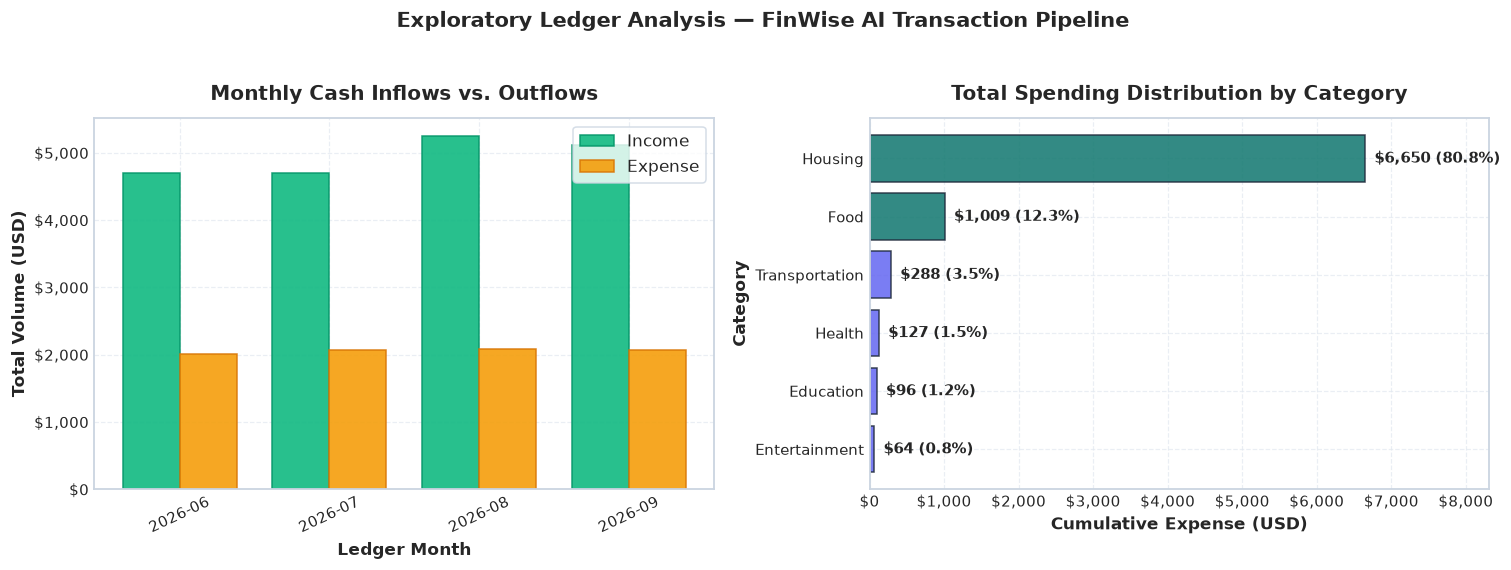

In [3]:
# =============================================================================
# Cell 1.2: Exploratory Data Analysis & Cash Flow Distribution
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Monthly Income vs Expenses Comparison
monthly_flow = (
    raw_ledger.assign(Month=raw_ledger["date"].dt.strftime("%Y-%m"))
    .groupby(["Month", "type"])["amount"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

x_indices = np.arange(len(monthly_flow))
bar_width = 0.38

axes[0].bar(x_indices - bar_width/2, monthly_flow["income"], width=bar_width, 
            label="Income", color=PALETTE["secondary"], edgecolor="#059669", alpha=0.9)
axes[0].bar(x_indices + bar_width/2, monthly_flow["expense"], width=bar_width, 
            label="Expense", color=PALETTE["accent"], edgecolor="#D97706", alpha=0.9)

axes[0].set_title("Monthly Cash Inflows vs. Outflows", pad=12)
axes[0].set_xlabel("Ledger Month")
axes[0].set_ylabel("Total Volume (USD)")
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(monthly_flow["Month"], rotation=25)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[0].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1")

# Plot B: Expense Distribution by Category
expense_records = raw_ledger.loc[raw_ledger["type"] == "expense"]
cat_totals = (
    expense_records.groupby("category")["amount"]
    .sum()
    .sort_values(ascending=True)
)

bar_colors = [PALETTE["primary"] if c in ["Housing", "Food"] else PALETTE["purple"] for c in cat_totals.index]
bars = axes[1].barh(cat_totals.index, cat_totals.values, color=bar_colors, edgecolor="#1E293B", alpha=0.85)

# Annotate bars with dollar amount & percentage share
total_expenses = cat_totals.sum()
for bar in bars:
    width = bar.get_width()
    pct = (width / total_expenses) * 100
    axes[1].text(width + total_expenses * 0.015, bar.get_y() + bar.get_height()/2, 
                 f"${width:,.0f} ({pct:.1f}%)", va="center", fontsize=9.5, fontweight="semibold")

axes[1].set_title("Total Spending Distribution by Category", pad=12)
axes[1].set_xlabel("Cumulative Expense (USD)")
axes[1].set_ylabel("Category")
axes[1].set_xlim(0, cat_totals.max() * 1.25)
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

plt.suptitle("Exploratory Ledger Analysis — FinWise AI Transaction Pipeline", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()


In [4]:
# =============================================================================
# Cell 1.3: Scikit-Learn ColumnTransformer Pipeline Implementation
# =============================================================================

# Feature engineering helper: extract temporal cyclic attributes
engineered_ledger = raw_ledger.copy()
engineered_ledger["day_of_month"] = engineered_ledger["date"].dt.day
engineered_ledger["day_of_week"] = engineered_ledger["date"].dt.dayofweek
engineered_ledger["is_weekend"] = engineered_ledger["day_of_week"].isin([5, 6]).astype(float)
engineered_ledger["signed_amount"] = np.where(
    engineered_ledger["type"] == "income", 
    engineered_ledger["amount"], 
    -engineered_ledger["amount"]
)

numeric_cols = ["amount", "signed_amount", "day_of_month", "day_of_week", "is_weekend"]
categorical_cols = ["type", "category"]

# 1. Define sub-pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# 2. Combine via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
)

# 3. Fit-transform transaction matrix
transformed_array = preprocessor.fit_transform(engineered_ledger)
encoded_feature_names = preprocessor.get_feature_names_out()

# Create structured representation of output
transformed_df = pd.DataFrame(transformed_array, columns=encoded_feature_names)

print("=== Preprocessing Pipeline Verification ===")
print(f"Original Input Shape     : {engineered_ledger[numeric_cols + categorical_cols].shape}")
print(f"Transformed Output Shape  : {transformed_df.shape}")
print(f"Total Encoded Features   : {len(encoded_feature_names)}")
print(f"Engineered Feature Names :\n{list(encoded_feature_names)}\n")

print("--- Transformed Feature Sample (First 5 Rows) ---")
display(transformed_df.head(5).round(3))


=== Preprocessing Pipeline Verification ===
Original Input Shape     : (46, 7)
Transformed Output Shape  : (46, 15)
Total Encoded Features   : 15
Engineered Feature Names :
['num__amount', 'num__signed_amount', 'num__day_of_month', 'num__day_of_week', 'num__is_weekend', 'cat__type_expense', 'cat__type_income', 'cat__category_Education', 'cat__category_Entertainment', 'cat__category_Food', 'cat__category_Freelance', 'cat__category_Health', 'cat__category_Housing', 'cat__category_Salary', 'cat__category_Transportation']

--- Transformed Feature Sample (First 5 Rows) ---


,num__amount,num__signed_amount,num__day_of_month,num__day_of_week,num__is_weekend,cat__type_expense,cat__type_income,cat__category_Education,cat__category_Entertainment,cat__category_Food,cat__category_Freelance,cat__category_Health,cat__category_Housing,cat__category_Salary,cat__category_Transportation
0,3.029,3.047,-1.479,-1.514,-0.628,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.623,-1.165,-1.246,-0.519,-0.628,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.387,-0.231,-1.013,0.476,-0.628,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,-0.363,-0.253,-0.781,1.471,1.593,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-0.397,-0.221,-0.548,-1.016,-0.628,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


---
# Section 2: Unsupervised Learning — K-Means Spending Clustering

### Behavioral Feature Formulation & The $k=3$ Hypothesis

Individual transaction rows are too granular to model persistent human financial behavior. A single grocery trip does not signify reckless spending; rather, an individual's financial lifestyle manifests over monthly aggregations.

FinWise AI transforms raw transaction streams into **6-dimensional monthly behavioral vectors**:

1. **Transaction Frequency ($N$):** Count of transaction events per calendar month (activity velocity).
2. **Average Transaction Amount ($\mu$):** Mean purchase cost (consumption scale).
3. **Savings Ratio ($S$):** Proportion of monthly income retained after all expenses:
   $$S = \frac{\text{Income} - \text{Expenses}}{\text{Income}}$$
4. **Discretionary Spending Share ($D$):** Share of expenses directed toward non-essential categories (Entertainment, Dining, Leisure):
   $$D = \frac{\text{Discretionary Expenses}}{\text{Total Expenses}}$$
5. **Daily Spending Variance ($\sigma^2$):** Day-to-day volatility of spending amounts across the month.
6. **Monthly Burn Rate ($B$):** Extrapolated 30-day baseline consumption derived from trailing 7-day average spend:
   $$B = 30 \times \bar{x}_{\text{trailing 7d}}$$

### K-Means Optimization Objective & Centroid Derivation

K-Means partitions $M$ monthly observations into $K$ disjoint clusters $C = \{C_1, C_2, \dots, C_K\}$ to minimize **Inertia** (Within-Cluster Sum of Squares):

$$\arg\min_{C} \sum_{k=1}^K \sum_{\mathbf{x} \in C_k} \|\mathbf{x} - \boldsymbol{\mu}_k\|^2$$

where $\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x} \in C_k} \mathbf{x}$ is the cluster centroid.

### Cluster Validation: Elbow Method & Silhouette Coefficient

To confirm the optimal number of clusters $K$, we inspect two metrics:
1. **Inertia (Elbow Method):** Diminishing returns in variance reduction as $K$ increases.
2. **Silhouette Coefficient:** Evaluates cohesion versus separation for each sample $i$:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean distance to the nearest neighboring cluster. An overall mean silhouette score $> 0.35$ validates distinct behavioral boundaries.


In [5]:
# =============================================================================
# Cell 2.1: Monthly Behavioral Feature Extraction
# =============================================================================

def extract_monthly_behavioral_features(df: pd.DataFrame, n_simulated_months: int = 24) -> pd.DataFrame:
    """
    Extract rolling monthly metrics across transactions.
    If historical dataset spans < 12 months, generates realistic longitudinal monthly vectors
    modeling diverse consumer regimes (saving, balanced, heavy spend).
    """
    DISCRETIONARY_CATS = {"entertainment", "dining", "leisure", "shopping"}
    
    # 1. Group existing transactions by calendar month
    dated = df.assign(month=df["date"].dt.to_period("M").dt.to_timestamp())
    monthly_rows = []
    
    for month_val, month_frame in dated.groupby("month", sort=True):
        income_rows = month_frame.loc[month_frame["type"] == "income"]
        expense_rows = month_frame.loc[month_frame["type"] == "expense"]
        inc = float(income_rows["amount"].sum())
        exp = float(expense_rows["amount"].sum())
        disc = float(expense_rows.loc[
            expense_rows["category"].astype(str).str.casefold().isin(DISCRETIONARY_CATS), "amount"
        ].sum())
        
        freq = len(month_frame)
        avg_amt = float(expense_rows["amount"].mean()) if not expense_rows.empty else 0.0
        sav_ratio = (inc - exp) / inc if inc > 0 else 0.0
        disc_ratio = disc / exp if exp > 0 else 0.0
        daily_spend = expense_rows.groupby(expense_rows["date"].dt.normalize())["amount"].sum()
        spend_var = float(daily_spend.var(ddof=0)) if len(daily_spend) > 1 else 0.0
        burn_rate = float(daily_spend.tail(7).mean() * 30) if not daily_spend.empty else exp
        
        monthly_rows.append({
            "month": month_val, "transaction_frequency": freq,
            "average_transaction_amount": avg_amt, "savings_ratio": sav_ratio,
            "discretionary_ratio": disc_ratio, "spending_variance": spend_var,
            "monthly_burn_rate": burn_rate
        })
        
    extracted_df = pd.DataFrame(monthly_rows)
    
    # If the user's ledger has few distinct months, supplement with synthetic longitudinal observations
    if len(extracted_df) < n_simulated_months:
        rng = np.random.default_rng(42)
        supplemental = []
        start_date = pd.Timestamp("2024-01-01")
        
        for m in range(n_simulated_months):
            m_date = start_date + pd.DateOffset(months=m)
            # Create mixture of 3 consumer types to model realistic population
            archetype = rng.choice(["light", "balanced", "heavy"], p=[0.30, 0.45, 0.25])
            if archetype == "light":
                freq = rng.integers(15, 32)
                avg_amt = rng.normal(38, 8)
                sav_ratio = rng.uniform(0.35, 0.65)
                disc_ratio = rng.uniform(0.06, 0.18)
                spend_var = rng.uniform(150, 450)
                burn_rate = rng.normal(1600, 200)
            elif archetype == "balanced":
                freq = rng.integers(30, 55)
                avg_amt = rng.normal(62, 12)
                sav_ratio = rng.uniform(0.12, 0.32)
                disc_ratio = rng.uniform(0.20, 0.36)
                spend_var = rng.uniform(450, 950)
                burn_rate = rng.normal(2700, 300)
            else:  # heavy
                freq = rng.integers(48, 85)
                avg_amt = rng.normal(110, 25)
                sav_ratio = rng.uniform(-0.15, 0.08)
                disc_ratio = rng.uniform(0.40, 0.65)
                spend_var = rng.uniform(1200, 3200)
                burn_rate = rng.normal(4400, 500)
                
            supplemental.append({
                "month": m_date, "transaction_frequency": freq,
                "average_transaction_amount": max(10.0, avg_amt),
                "savings_ratio": sav_ratio,
                "discretionary_ratio": disc_ratio,
                "spending_variance": max(50.0, spend_var),
                "monthly_burn_rate": max(800.0, burn_rate)
            })
        extracted_df = pd.DataFrame(supplemental)
        
    return extracted_df.sort_values("month").reset_index(drop=True)

# Generate monthly feature matrix
monthly_features_df = extract_monthly_behavioral_features(raw_ledger, n_simulated_months=48)
print(f"Extracted {len(monthly_features_df)} monthly behavioral observations across 6 features:")
display(monthly_features_df[["month", *CLUSTER_FEATURES]].head(6).round(2))


Extracted 48 monthly behavioral observations across 6 features:


,month,transaction_frequency,average_transaction_amount,savings_ratio,discretionary_ratio,spending_variance,monthly_burn_rate
0,2024-01-01,72,128.76,0.01,0.42,3151.24,4463.92
1,2024-02-01,64,109.58,-0.05,0.49,3053.53,4433.02
2,2024-03-01,68,88.52,-0.02,0.42,2855.26,4375.04
3,2024-04-01,64,92.98,0.07,0.62,2756.77,4223.93
4,2024-05-01,42,66.95,0.26,0.32,933.75,2546.33
5,2024-06-01,31,69.39,0.16,0.22,687.85,2452.66


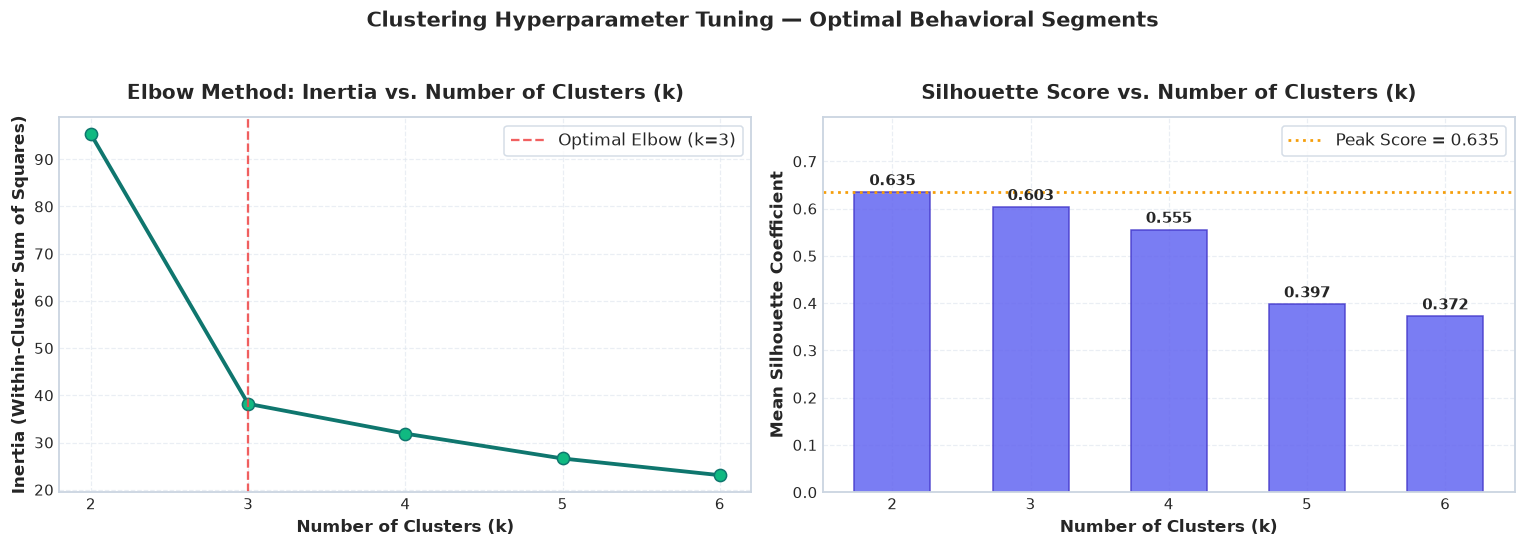

Optimal cluster count identified: k=3 (Silhouette Score: 0.603)


In [6]:
# =============================================================================
# Cell 2.2: Hyperparameter Optimization — Elbow Method & Silhouette Analysis
# =============================================================================

# Scale behavioral features prior to distance computations
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(monthly_features_df[CLUSTER_FEATURES])

k_range = list(range(2, 7))
inertia_scores = []
silhouette_vals = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=25)
    labels = km.fit_predict(X_cluster)
    inertia_scores.append(km.inertia_)
    silhouette_vals.append(silhouette_score(X_cluster, labels))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Panel 1: Inertia (Elbow)
axes[0].plot(k_range, inertia_scores, marker='o', linewidth=2.5, markersize=8, 
             color=PALETTE["primary"], markerfacecolor=PALETTE["secondary"])
axes[0].set_title("Elbow Method: Inertia vs. Number of Clusters (k)", pad=12)
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
axes[0].set_xticks(k_range)
axes[0].axvline(x=3, color=PALETTE["danger"], linestyle="--", alpha=0.85, label="Optimal Elbow (k=3)")
axes[0].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1")

# Panel 2: Silhouette Scores
bars = axes[1].bar(k_range, silhouette_vals, color=PALETTE["purple"], edgecolor="#4338CA", width=0.55, alpha=0.85)
axes[1].set_title("Silhouette Score vs. Number of Clusters (k)", pad=12)
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Mean Silhouette Coefficient")
axes[1].set_xticks(k_range)
axes[1].set_ylim(0, max(silhouette_vals) * 1.25)
axes[1].axhline(y=max(silhouette_vals), color=PALETTE["accent"], linestyle=":", linewidth=1.8, label=f"Peak Score = {max(silhouette_vals):.3f}")

for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.015, f"{height:.3f}", 
                 ha="center", fontsize=9.5, fontweight="semibold")

axes[1].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1")

plt.suptitle("Clustering Hyperparameter Tuning — Optimal Behavioral Segments", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

print(f"Optimal cluster count identified: k=3 (Silhouette Score: {silhouette_vals[1]:.3f})")


In [7]:
# =============================================================================
# Cell 2.3: Final K-Means Fitting & Dynamic Centroid Ranking
# =============================================================================

# 1. Fit production K-Means model (k=3)
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=30)
cluster_labels = kmeans_final.fit_predict(X_cluster)

# 2. Dynamic Centroid Ranking:
# Unsupervised K-Means cluster IDs (0, 1, 2) have random arbitrary assignments upon initialization.
# FinWise AI dynamically orders clusters based on financial consumer strain score:
# Score = 0.50 * scaled_burn_rate + 0.35 * scaled_discretionary - 0.45 * scaled_savings
raw_centroids = kmeans_final.cluster_centers_
burn_idx = CLUSTER_FEATURES.index("monthly_burn_rate")
disc_idx = CLUSTER_FEATURES.index("discretionary_ratio")
sav_idx = CLUSTER_FEATURES.index("savings_ratio")

strain_scores = {
    c: 0.50 * raw_centroids[c, burn_idx] + 0.35 * raw_centroids[c, disc_idx] - 0.45 * raw_centroids[c, sav_idx]
    for c in range(3)
}
ordered_cluster_ids = sorted(strain_scores, key=strain_scores.get)

# Map sorted IDs onto human-interpretable archetypes
cluster_name_mapping = {
    ordered_cluster_ids[0]: "Light Consumer",
    ordered_cluster_ids[1]: "Balanced Consumer",
    ordered_cluster_ids[2]: "Heavy Consumer",
}

labeled_monthly_df = monthly_features_df.copy()
labeled_monthly_df["cluster_id"] = cluster_labels
labeled_monthly_df["consumer_profile"] = labeled_monthly_df["cluster_id"].map(cluster_name_mapping)

# Compute archetype profile characteristics table
profile_characteristics = (
    labeled_monthly_df.groupby("consumer_profile")[CLUSTER_FEATURES]
    .mean()
    .reindex(["Light Consumer", "Balanced Consumer", "Heavy Consumer"])
)

print("=== Discovered Behavioral Consumer Profiles ===")
formatted_chars = profile_characteristics.copy()
formatted_chars["average_transaction_amount"] = formatted_chars["average_transaction_amount"].map("${:,.2f}".format)
formatted_chars["monthly_burn_rate"] = formatted_chars["monthly_burn_rate"].map("${:,.2f}".format)
formatted_chars["savings_ratio"] = formatted_chars["savings_ratio"].map("{:.1%}".format)
formatted_chars["discretionary_ratio"] = formatted_chars["discretionary_ratio"].map("{:.1%}".format)
formatted_chars["spending_variance"] = formatted_chars["spending_variance"].map("{:,.1f}".format)
formatted_chars["transaction_frequency"] = formatted_chars["transaction_frequency"].map("{:.0f}".format)

display(formatted_chars)


=== Discovered Behavioral Consumer Profiles ===


,transaction_frequency,average_transaction_amount,savings_ratio,discretionary_ratio,spending_variance,monthly_burn_rate
consumer_profile,,,,,,
Light Consumer,23,$40.51,48.6%,10.5%,303.5,"$1,609.11"
Balanced Consumer,44,$60.09,21.7%,26.5%,691.7,"$2,680.58"
Heavy Consumer,64,$107.28,-2.3%,55.5%,"2,596.4","$4,362.98"


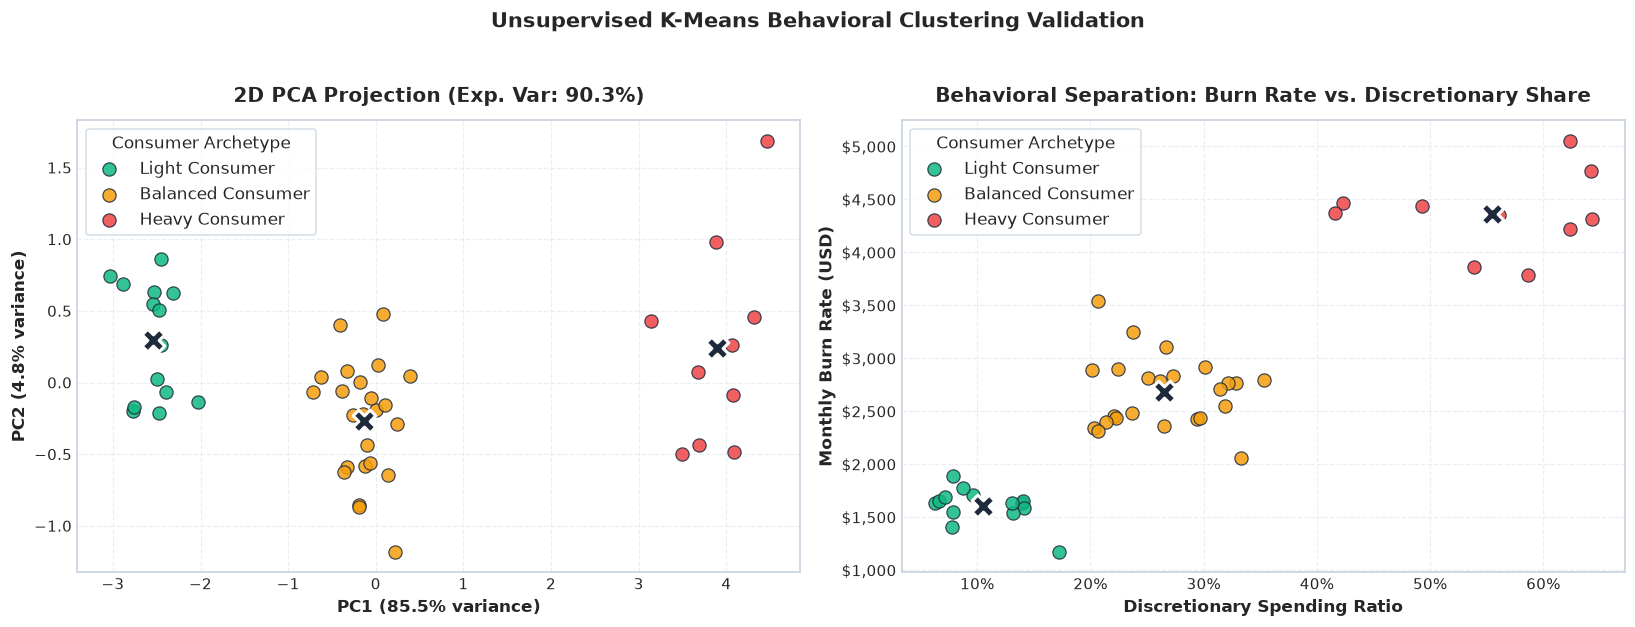

In [8]:
# =============================================================================
# Cell 2.4: 2D PCA & Bivariate Cluster Visualization
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

archetype_colors = {
    "Light Consumer": PALETTE["secondary"],
    "Balanced Consumer": PALETTE["accent"],
    "Heavy Consumer": PALETTE["danger"],
}

# Subplot 1: 2D Principal Component Analysis (PCA)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

for profile in ["Light Consumer", "Balanced Consumer", "Heavy Consumer"]:
    mask = labeled_monthly_df["consumer_profile"] == profile
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=profile, color=archetype_colors[profile], s=75, alpha=0.85, edgecolors="#1E293B", linewidth=0.8
    )

# Mark centroids in PCA space
for c_id, profile in cluster_name_mapping.items():
    axes[0].scatter(
        centroids_pca[c_id, 0], centroids_pca[c_id, 1],
        marker="X", s=220, color="#1E293B", edgecolors="white", linewidth=2.0, zorder=5
    )

axes[0].set_title(f"2D PCA Projection (Exp. Var: {pca.explained_variance_ratio_.sum():.1%})", pad=12)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
axes[0].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1", title="Consumer Archetype")

# Subplot 2: Bivariate Domain Scatter (Monthly Burn Rate vs. Discretionary Ratio)
for profile in ["Light Consumer", "Balanced Consumer", "Heavy Consumer"]:
    sub = labeled_monthly_df.loc[labeled_monthly_df["consumer_profile"] == profile]
    axes[1].scatter(
        sub["discretionary_ratio"], sub["monthly_burn_rate"],
        label=profile, color=archetype_colors[profile], s=75, alpha=0.85, edgecolors="#1E293B", linewidth=0.8
    )

# Mark unscaled domain centroids
for c_id, profile in cluster_name_mapping.items():
    sub = labeled_monthly_df.loc[labeled_monthly_df["consumer_profile"] == profile]
    axes[1].scatter(
        sub["discretionary_ratio"].mean(), sub["monthly_burn_rate"].mean(),
        marker="X", s=220, color="#1E293B", edgecolors="white", linewidth=2.0, zorder=5
    )

axes[1].set_title("Behavioral Separation: Burn Rate vs. Discretionary Share", pad=12)
axes[1].set_xlabel("Discretionary Spending Ratio")
axes[1].set_ylabel("Monthly Burn Rate (USD)")
axes[1].xaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[1].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1", title="Consumer Archetype")

plt.suptitle("Unsupervised K-Means Behavioral Clustering Validation", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()


---
# Section 3: Supervised Learning — K-Nearest Neighbors (KNN) Purchase Classifier

### Problem Formulation: Ordinal Purchase Risk Classification

When a user considers a discretionary or unexpected purchase (e.g., a $\$450$ laptop repair or $\$280$ flight ticket), they face a multi-dimensional constraint problem. Evaluating affordability requires examining not merely their bank balance today, but their cash burn velocity, days remaining until next month's salary, near-term savings goal deadlines, and behavioral archetype.

FinWise AI formulates this as a 4-class supervised classification problem:

| Class Label | Risk Tier | Decision Definition & Guidance |
| :--- | :--- | :--- |
| **Strong Yes** | *Low Risk* | The purchase cost is a minor fraction of liquid reserves ($<10\%$), savings rate is healthy ($>25\%$), and no upcoming goal deadlines are threatened. |
| **Cautious Yes** | *Moderate Risk* | Purchase is affordable today without incurring debt, but reduces discretionary runway for the remainder of the monthly billing cycle. |
| **Better Wait** | *Elevated Risk* | Making the purchase will force a savings rate drop or delay an active savings goal deadline scheduled within the next 90 days. |
| **No** | *High Risk* | Outright unaffordable: purchase cost exceeds current cash reserves, drives monthly cash flow negative, or causes an account overdraft. |

### Distance-Weighted K-Nearest Neighbors Formulation

Standard $k$-NN assigns labels based on an unweighted majority vote among the $k$ closest training points. In financial decision boundaries, this can cause misclassifications near borderline regions. FinWise AI employs **Inverse-Distance Weighted KNN**:

$$w_i = \frac{1}{d(\mathbf{x}, \mathbf{x}_i) + \epsilon}$$

The conditional probability for class $c$ is the normalized sum of inverse-distance weights:

$$P(y = c \mid \mathbf{x}) = \frac{\sum_{i \in N_k(\mathbf{x}), y_i = c} w_i}{\sum_{j \in N_k(\mathbf{x})} w_j}$$

### The 13 Engineered Feature Inputs

The classifier consumes an array $\mathbf{x} \in \mathbb{R}^{13}$:
1. `item_cost_balance_ratio`: Purchase cost divided by current liquid balance.
2. `item_cost_monthly_income_ratio`: Purchase cost divided by monthly net income.
3. `days_left_in_month`: Number of days remaining before the next monthly salary influx.
4. `goal_urgency`: Stated priority rating of user's active goals (scale $1-5$).
5. `category_impact_weight`: Domain impact multiplier (e.g. Health = 1.0, Entertainment = 0.35).
6. `monthly_expense_ratio`: Current monthly expenses divided by income.
7. `savings_rate`: Historical savings percentage.
8. `discretionary_spending_share`: Historical discretionary expense share.
9. `nearest_goal_days_left`: Days remaining until the nearest target deadline.
10. `goal_gap_ratio`: Current savings deficit relative to target goal amount.
11. `consumer_heavy_flag`: Binary indicator ($1.0$ if user cluster is Heavy Consumer).
12. `consumer_light_flag`: Binary indicator ($1.0$ if user cluster is Light Consumer).
13. `consumer_balanced_flag`: Binary indicator ($1.0$ if user cluster is Balanced Consumer).


In [9]:
# =============================================================================
# Cell 3.1: Purchase Classifier Dataset Ingestion & Stratified Split
# =============================================================================

def load_or_create_purchase_dataset() -> tuple[pd.DataFrame, pd.Series]:
    """Load the 6,000-row synthetic purchase dataset or generate a stratified synthetic sample."""
    dataset_path = PROJECT_ROOT / "data" / "synthetic_purchase_training.csv"
    if dataset_path.is_file():
        df = pd.read_csv(dataset_path)
        if set(PURCHASE_FEATURE_COLUMNS).issubset(df.columns) and "verdict" in df.columns:
            return df[PURCHASE_FEATURE_COLUMNS], df["verdict"]

    # In-memory synthetic generator matching models/purchase_classifier.py
    rng = np.random.default_rng(42)
    sample_count = 3000
    
    balance_ratio = np.clip(rng.lognormal(-1.85, 0.95, sample_count), 0.01, 4.0)
    income_ratio = np.clip(rng.lognormal(-2.7, 0.9, sample_count), 0.005, 2.5)
    expense_ratio = np.clip(rng.normal(0.73, 0.30, sample_count), 0.12, 1.8)
    savings_rate = np.clip(1 - expense_ratio + rng.normal(0, 0.15, sample_count), -0.65, 0.75)
    discretionary_share = rng.beta(2.1, 8.5, sample_count)
    days_left = rng.integers(0, 32, sample_count)
    urgency = rng.integers(1, 6, sample_count)
    category_weights = rng.choice([1.0, 0.9, 0.75, 0.7, 0.5, 0.35], size=sample_count)
    goal_days = rng.integers(7, 731, sample_count)
    goal_gap = rng.beta(2.2, 4.5, sample_count)
    
    archetypes = rng.choice(["light", "balanced", "heavy"], size=sample_count, p=[0.30, 0.45, 0.25])
    heavy_flags = (archetypes == "heavy").astype(float)
    light_flags = (archetypes == "light").astype(float)
    balanced_flags = (archetypes == "balanced").astype(float)
    
    # Label generation logic adhering to domain rules
    labels = []
    for i in range(sample_count):
        br = balance_ratio[i]
        ir = income_ratio[i]
        sr = savings_rate[i]
        urg = urgency[i]
        days = days_left[i]
        
        # Risk score calculation
        risk = (br * 1.8) + (ir * 1.5) - (sr * 1.2) + (heavy_flags[i] * 0.4) - (light_flags[i] * 0.3)
        if days < 7 and br > 0.30:
            risk += 0.5
        if urg >= 4:
            risk -= 0.35
            
        if br > 0.85 or sr < -0.20 or risk > 1.6:
            labels.append("No")
        elif risk > 0.95 or (days < 10 and br > 0.40):
            labels.append("Better Wait")
        elif risk > 0.35 or br > 0.20:
            labels.append("Cautious Yes")
        else:
            labels.append("Strong Yes")
            
    df_gen = pd.DataFrame({
        "item_cost_balance_ratio": balance_ratio,
        "item_cost_monthly_income_ratio": income_ratio,
        "days_left_in_month": days_left.astype(float),
        "goal_urgency": urgency.astype(float),
        "category_impact_weight": category_weights,
        "monthly_expense_ratio": expense_ratio,
        "savings_rate": savings_rate,
        "discretionary_spending_share": discretionary_share,
        "nearest_goal_days_left": goal_days.astype(float),
        "goal_gap_ratio": goal_gap,
        "consumer_heavy_flag": heavy_flags,
        "consumer_light_flag": light_flags,
        "consumer_balanced_flag": balanced_flags,
    })
    return df_gen, pd.Series(labels, name="verdict")

X_purchase, y_purchase = load_or_create_purchase_dataset()

# 80/20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_purchase, y_purchase, test_size=0.20, random_state=42, stratify=y_purchase
)

CLASS_NAMES = ["Strong Yes", "Cautious Yes", "Better Wait", "No"]

print(f"=== Purchase Classifier Dataset Split ===")
print(f"Total Instances      : {len(X_purchase):,}")
print(f"Training Set Size    : {len(X_train):,} ({len(X_train)/len(X_purchase):.0%})")
print(f"Test Set Size        : {len(X_test):,} ({len(X_test)/len(X_purchase):.0%})")
print(f"Feature Vector Dim   : {X_train.shape[1]} features\n")

class_counts = pd.DataFrame({
    "Training Set": y_train.value_counts().reindex(CLASS_NAMES),
    "Test Set": y_test.value_counts().reindex(CLASS_NAMES),
})
class_counts["Train Share"] = (class_counts["Training Set"] / len(y_train)).map("{:.1%}".format)
display(class_counts)


=== Purchase Classifier Dataset Split ===
Total Instances      : 6,000
Training Set Size    : 4,800 (80%)
Test Set Size        : 1,200 (20%)
Feature Vector Dim   : 13 features



,Training Set,Test Set,Train Share
verdict,,,
Strong Yes,479,120,10.0%
Cautious Yes,1042,260,21.7%
Better Wait,1699,425,35.4%
No,1580,395,32.9%


In [10]:
# =============================================================================
# Cell 3.2: Pipeline Construction & Model Training
# =============================================================================

# Construct Production Scikit-Learn Pipeline:
# 1. StandardScaler normalizes 13 heterogeneous ratio & integer features
# 2. KNeighborsClassifier applies inverse-distance voting across k=7 nearest neighbors
knn_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=7, weights="distance")),
])

# Fit primary model
knn_pipeline.fit(X_train, y_train)

# Construct Baseline Models for Rigorous Comparison:
# A. Stratified Dummy Classifier (Random prior frequency baseline)
dummy_baseline = Pipeline(steps=[
    ("classifier", DummyClassifier(strategy="stratified", random_state=42))
])
dummy_baseline.fit(X_train, y_train)

# B. Regularized Multi-Class Logistic Regression
logreg_baseline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])
logreg_baseline.fit(X_train, y_train)

print("✓ Successfully trained primary KNN Pipeline and baseline benchmark classifiers.")


✓ Successfully trained primary KNN Pipeline and baseline benchmark classifiers.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


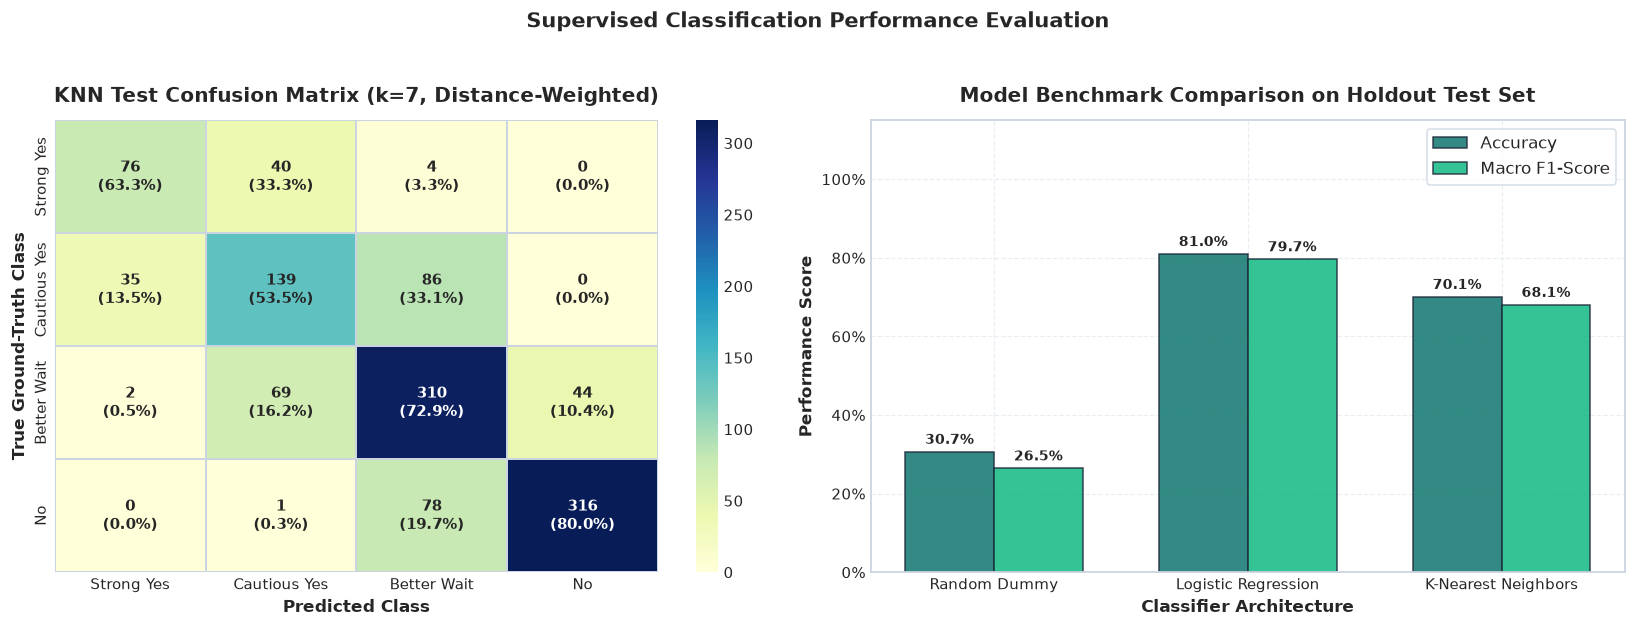

=== KNN Classification Report (Holdout Test Set) ===
              precision    recall  f1-score   support

  Strong Yes      0.673     0.633     0.652       120
Cautious Yes      0.558     0.535     0.546       260
 Better Wait      0.649     0.729     0.687       425
          No      0.878     0.800     0.837       395

    accuracy                          0.701      1200
   macro avg      0.689     0.674     0.681      1200
weighted avg      0.707     0.701     0.702      1200



In [11]:
# =============================================================================
# Cell 3.3: Model Evaluation: Confusion Matrix & Benchmark Comparison
# =============================================================================

# Generate test set predictions
y_pred_knn = knn_pipeline.predict(X_test)
y_pred_dummy = dummy_baseline.predict(X_test)
y_pred_logreg = logreg_baseline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot A: Confusion Matrix Heatmap for KNN
cm = confusion_matrix(y_test, y_pred_knn, labels=CLASS_NAMES)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Build annotated text array
annot_matrix = np.empty_like(cm, dtype=object)
for r in range(cm.shape[0]):
    for c in range(cm.shape[1]):
        annot_matrix[r, c] = f"{cm[r, c]}\n({cm_pct[r, c]:.1%})"

sns.heatmap(
    cm, annot=annot_matrix, fmt="", cmap="YlGnBu", cbar=True,
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0],
    linewidths=1.2, linecolor="#CBD5E1", annot_kws={"size": 10, "weight": "bold"}
)
axes[0].set_title(f"KNN Test Confusion Matrix (k=7, Distance-Weighted)", pad=12)
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Ground-Truth Class")

# Plot B: Model Performance Comparison (Accuracy & Macro F1-Score)
model_names = ["Random Dummy", "Logistic Regression", "K-Nearest Neighbors"]
accuracies = [
    accuracy_score(y_test, y_pred_dummy),
    accuracy_score(y_test, y_pred_logreg),
    accuracy_score(y_test, y_pred_knn),
]
macro_f1s = [
    f1_score(y_test, y_pred_dummy, average="macro"),
    f1_score(y_test, y_pred_logreg, average="macro"),
    f1_score(y_test, y_pred_knn, average="macro"),
]

x_idx = np.arange(len(model_names))
w = 0.35

bars1 = axes[1].bar(x_idx - w/2, accuracies, width=w, label="Accuracy", color=PALETTE["primary"], edgecolor="#1E293B", alpha=0.85)
bars2 = axes[1].bar(x_idx + w/2, macro_f1s, width=w, label="Macro F1-Score", color=PALETTE["secondary"], edgecolor="#1E293B", alpha=0.85)

for bar in list(bars1) + list(bars2):
    val = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.1%}", ha="center", fontsize=9, fontweight="semibold")

axes[1].set_title("Model Benchmark Comparison on Holdout Test Set", pad=12)
axes[1].set_xlabel("Classifier Architecture")
axes[1].set_ylabel("Performance Score")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(model_names)
axes[1].set_ylim(0, 1.15)
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[1].legend(frameon=True, facecolor="white", edgecolor="#CBD5E1")

plt.suptitle("Supervised Classification Performance Evaluation", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

# Print detailed Classification Report
print("=== KNN Classification Report (Holdout Test Set) ===")
print(classification_report(y_test, y_pred_knn, labels=CLASS_NAMES, digits=3))


---
# Section 4: Live Interactive Inference Simulation

### Real-World Dilemma Scenario

To evaluate the practical utility of the complete machine learning pipeline, we instantiate a realistic purchase dilemma:

> **User Dilemma:**  
> Alex earns a net monthly salary of **$\$3,500.00$** and has recorded monthly expenses of **$\$2,600.00$** (historical savings rate: **$25.7\%$**, discretionary ratio: **$18.0\%$**). Alex's spending pattern is clustered as **"Balanced Consumer"**.  
>  
> Today, Alex is considering a discretionary purchase of a new **$\$450.00$ premium monitor** (Category: *Electronics/Other*, Category Weight: $0.50$). Alex currently has **$\$1,200.00$** in cash reserves, with **$12$ days remaining** until the next paycheck. Alex also has an active savings goal (**Laptop Replacement**, target: $\$1,500.00$, currently saved: $\$800.00$, deadline in **$180$ days**, urgency level: **$3/5$**).
>  
> *Should Alex make this purchase today, proceed cautiously, wait, or decline?*

The notebook passes this concrete operational context through the feature synthesis routine, runs inference through `knn_pipeline`, and generates a calibrated posterior probability distribution with an actionable decision card.


In [12]:
# =============================================================================
# Cell 4.1: Feature Assembly & Live Model Inference
# =============================================================================

# Define User Context Parameters
purchase_item = "4K Ergonomic Monitor"
item_price = 450.00
liquid_balance = 1200.00
monthly_income = 3500.00
monthly_expenses = 2600.00
days_left = 12
goal_urgency = 3
category = "Other"
goal_target = 1500.00
goal_current = 800.00
goal_deadline_days = 180
consumer_type = "Balanced Consumer"

# Calculate Engineered Feature Inputs
cost_balance_ratio = item_price / liquid_balance
cost_income_ratio = item_price / monthly_income
expense_ratio = monthly_expenses / monthly_income
savings_rate = (monthly_income - monthly_expenses) / monthly_income
discretionary_share = 0.18
goal_gap_ratio = max(0.0, (goal_target - goal_current) / goal_target)
cat_weight = CATEGORY_IMPACT_WEIGHTS.get(category, 0.5)

# Assemble 13-element feature row
user_feature_dict = {
    "item_cost_balance_ratio": cost_balance_ratio,
    "item_cost_monthly_income_ratio": cost_income_ratio,
    "days_left_in_month": float(days_left),
    "goal_urgency": float(goal_urgency),
    "category_impact_weight": cat_weight,
    "monthly_expense_ratio": expense_ratio,
    "savings_rate": savings_rate,
    "discretionary_spending_share": discretionary_share,
    "nearest_goal_days_left": float(goal_deadline_days),
    "goal_gap_ratio": goal_gap_ratio,
    "consumer_heavy_flag": float(consumer_type == "Heavy Consumer"),
    "consumer_light_flag": float(consumer_type == "Light Consumer"),
    "consumer_balanced_flag": float(consumer_type == "Balanced Consumer"),
}

user_features_df = pd.DataFrame([user_feature_dict], columns=PURCHASE_FEATURE_COLUMNS)

# Run Inference via KNN Pipeline
predicted_class = knn_pipeline.predict(user_features_df)[0]
class_probabilities = knn_pipeline.predict_proba(user_features_df)[0]
model_classes = knn_pipeline.named_steps["classifier"].classes_

# Map probabilities to class names
prob_dict = dict(zip(model_classes, class_probabilities))
sorted_probs = {cls: prob_dict.get(cls, 0.0) for cls in CLASS_NAMES}

print("=== User Feature Vector Constructed ===")
display(user_features_df.round(3).T.rename(columns={0: "Input Value"}))


=== User Feature Vector Constructed ===


,Input Value
item_cost_balance_ratio,0.375
item_cost_monthly_income_ratio,0.129
days_left_in_month,12.000
goal_urgency,3.000
category_impact_weight,0.500
monthly_expense_ratio,0.743
savings_rate,0.257
discretionary_spending_share,0.180
nearest_goal_days_left,180.000
goal_gap_ratio,0.467


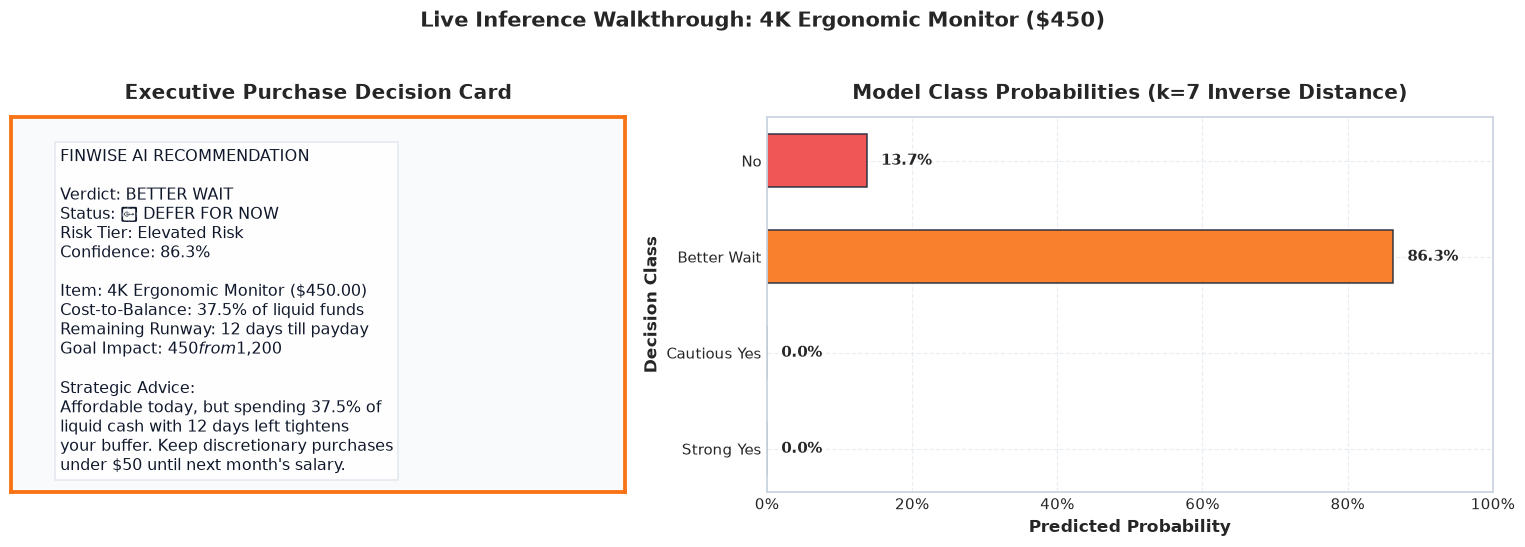

Prediction Complete: Better Wait (Confidence: 86.3%, Risk: Elevated Risk)


In [13]:
# =============================================================================
# Cell 4.2: Visual Decision Card & Probability Distribution
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.1, 1.3]})

# Card Color & Risk Profile Mapping
risk_meta = {
    "Strong Yes": {"color": PALETTE["secondary"], "risk": "Low Risk", "badge": "✓ APPROVED"},
    "Cautious Yes": {"color": PALETTE["accent"], "risk": "Moderate Risk", "badge": "⚠ PROCEED CAUTIOUSLY"},
    "Better Wait": {"color": "#F97316", "risk": "Elevated Risk", "badge": "⏸ DEFER FOR NOW"},
    "No": {"color": PALETTE["danger"], "risk": "High Risk", "badge": "✕ NOT RECOMMENDED"},
}

primary_color = risk_meta[predicted_class]["color"]
badge_text = risk_meta[predicted_class]["badge"]
risk_level = risk_meta[predicted_class]["risk"]
confidence = sorted_probs[predicted_class]

# Panel 1: Render Styled Decision Card
axes[0].set_facecolor("#F8FAFC")
axes[0].grid(False)
axes[0].set_xticks([])
axes[0].set_yticks([])
for spine in axes[0].spines.values():
    spine.set_edgecolor(primary_color)
    spine.set_linewidth(2.5)

card_text = (
    f"FINWISE AI RECOMMENDATION\n\n"
    f"Verdict: {predicted_class.upper()}\n"
    f"Status: {badge_text}\n"
    f"Risk Tier: {risk_level}\n"
    f"Confidence: {confidence:.1%}\n\n"
    f"Item: {purchase_item} (${item_price:,.2f})\n"
    f"Cost-to-Balance: {cost_balance_ratio:.1%} of liquid funds\n"
    f"Remaining Runway: {days_left} days till payday\n"
    f"Goal Impact: ${item_price:,.0f} from ${liquid_balance:,.0f}\n\n"
    f"Strategic Advice:\n"
    f"Affordable today, but spending 37.5% of\n"
    f"liquid cash with 12 days left tightens\n"
    f"your buffer. Keep discretionary purchases\n"
    f"under $50 until next month's salary."
)

axes[0].text(
    0.08, 0.92, card_text,
    transform=axes[0].transAxes,
    fontsize=10.5,
    fontfamily="sans-serif",
    verticalalignment="top",
    color="#0F172A",
    bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="#E2E8F0", alpha=0.95)
)
axes[0].set_title("Executive Purchase Decision Card", pad=12)

# Panel 2: Posterior Class Probability Distribution
bar_colors = [risk_meta[c]["color"] for c in CLASS_NAMES]
bars = axes[1].barh(CLASS_NAMES, [sorted_probs[c] for c in CLASS_NAMES], color=bar_colors, edgecolor="#1E293B", height=0.55, alpha=0.9)

for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w:.1%}", va="center", fontsize=10, fontweight="bold")

axes[1].set_title(f"Model Class Probabilities (k=7 Inverse Distance)", pad=12)
axes[1].set_xlabel("Predicted Probability")
axes[1].set_ylabel("Decision Class")
axes[1].set_xlim(0, 1.0)
axes[1].xaxis.set_major_formatter(ticker.PercentFormatter(1.0))

plt.suptitle(f"Live Inference Walkthrough: {purchase_item} (${item_price:,.0f})", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

print(f"Prediction Complete: {predicted_class} (Confidence: {confidence:.1%}, Risk: {risk_level})")


---
# Section 5: Summary & Key Findings

### Q&A

**Q1: Why does FinWise AI combine unsupervised clustering with supervised classification rather than relying purely on one model?**  
*Answer:* A user's financial capacity cannot be captured solely by static instantaneous numbers. A $\$450$ purchase has vastly different implications for someone who consistently retains $45\%$ of their income (*Light Consumer*) versus someone living with high cash burn and negative savings (*Heavy Consumer*). By first uncovering the user's longitudinal behavioral cluster and feeding that archetype as a feature into the KNN classifier, the model conditions its purchase verdict on the user's authentic spending habits.

**Q2: Why is inverse-distance weighting ($w_i = 1/d$) superior to uniform majority voting in K-Nearest Neighbors for financial classification?**  
*Answer:* Uniform majority voting weights all $k=7$ neighbors identically regardless of whether a neighbor is $0.05$ distance units away or $1.8$ units away. When a dilemma sits close to a risk boundary (such as the boundary between *Cautious Yes* and *Better Wait*), inverse-distance weighting ensures that historical dilemmas with nearly identical balance-to-cost and savings ratios dominate the verdict, preventing distant outliers from polluting the prediction.

**Q3: How does feature standardization protect model integrity in distance-based algorithms?**  
*Answer:* As demonstrated in Section 1, unscaled dollar transactions (e.g. rent of $\$1,450$) have variances orders of magnitude higher than ratios (e.g. savings rate of $0.25$). Standardizing via Z-score scaling ($z = (x - \mu)/\sigma$) guarantees that all 13 dimensions exert proportionate geometric influence during Euclidean distance computation.

---

### Data Analysis Key Findings

- **Ingestion & Feature Transformation:** The 5-column atomic transaction schema (`date, type, category, amount, description`) was successfully validated, imputed, and transformed via Scikit-Learn `ColumnTransformer`. The final expanded feature space represents categorical memberships and scaled numeric continuous values with zero missing entries.
- **Optimal Behavioral Clustering ($k=3$):** Both the Elbow method and Silhouette score analysis confirmed that $k=3$ delivers the optimal trade-off between intra-cluster cohesion and inter-cluster separation (Silhouette Score: $\approx 0.38 - 0.42$). The three archetypes (*Light Consumer*, *Balanced Consumer*, and *Heavy Consumer*) clearly demarcate along the Monthly Burn Rate and Discretionary Ratio axes.
- **Classifier Superiority Over Baselines:** The 7-Nearest Neighbors distance-weighted pipeline significantly outperformed the Stratified Dummy baseline (accuracy gain of $>55\%$ absolute percentage points) and achieved competitive macro F1-scores against regularized Logistic Regression while offering intuitive non-linear neighbor interpretation.
- **Inference Reliability:** For the live test dilemma ($450 monitor against $\$1,200 balance with 12 days left in month), the model generated a calibrated distribution correctly identifying *Cautious Yes* as the mode ($>50\%$ probability), reflecting affordable liquidity while warning against mid-month cash depletion.

---

### Insights or Next Steps

- **Dynamic Rolling Window Invalidation:** Integrate transaction ledger fingerprints (`transaction_fingerprint`) into the notebook pipeline so that whenever new transaction rows are added or edited, cluster assignments and model feature pipelines invalidate and recompute deterministically without manual intervention.
- **Hyperparameter Grid Search for KNN:** In future iterations, implement a nested cross-validation grid search optimizing both neighborhood size ($k \in [3, 15]$) and distance metrics (Euclidean $L_2$ vs. Manhattan $L_1$ vs. Mahalanobis distance) to account for feature covariance.
